# Active calibration (direction B) on UBP

For a new user, which images should they view during calibration so a decoder pretrained on other subjects adapts best,
counted in recorded presentations? Code: `activecal.py` (experiment) on top of `ubpkd.py` (UBP data, models, training),
both in this repo. Results go to `activecal.csv` on Drive and are committed to `results/` in the repo by the last cell.

**Run order:** 1–5 once per runtime, then 6 (diagnostics) → 7 (gate) → 8 (main, after setting the frozen adapter) → 9.
Every experiment cell is resumable: finished runs are skipped by tag. Use an L4 GPU with High-RAM.

In [1]:
# 1. GPU, code (this repo, latest main), UBP code (pinned), packages. Private repo: add a GITHUB_TOKEN Colab secret.
import os
from google.colab import userdata
REPO = 'navyers21/eeg_active_calibration'
try:
    TOKEN = userdata.get('GITHUB_TOKEN'); URL = f'https://{TOKEN}@github.com/{REPO}'
except Exception:
    TOKEN, URL = None, f'https://github.com/{REPO}'
!nvidia-smi --query-gpu=name,memory.total --format=csv
!free -g | head -2
!git clone -q {URL} /content/eac 2>/dev/null || git -C /content/eac pull -q
!git -C /content/eac log --oneline -1
!git clone -q https://github.com/HaitaoWuTJU/Uncertainty-aware-Blur-Prior /content/ubp 2>/dev/null || true
!git -C /content/ubp checkout -q 2e513ae && git -C /content/ubp log --oneline -1
!pip -q install open_clip_torch==2.29.0 einops omegaconf hf_transfer

name, memory.total [MiB]
NVIDIA L4, 23034 MiB
               total        used        free      shared  buff/cache   available
Mem:              52           1          48           0           3          51
d8702aa (HEAD -> main, origin/main, origin/HEAD) Add active calibration (direction B) pipeline
2e513ae (HEAD, origin/main, origin/HEAD, main) fig bug


In [2]:
# 2. Configuration
SUBJECTS = list(range(1, 11))     # every subject: each non-target subject is a source for the LOSO decoder
SCREEN   = [2, 5, 9]              # screening subjects (targets), chosen in advance
TARGETS  = SCREEN + [8]
TUNE_SUB = 1                      # diagnostics and gate only, never a target
MONTAGES = ['occipital8', 'posterior17']   # Crown-8 dropped: f0 and ceiling both ~1%, no headroom
SEEDS    = [0, 1, 2]
SOURCE   = 'hf_whiten'            # rerun the winner with 'clean_mvnn' before any final channel claim
DRIVE_BASE = '/content/drive/MyDrive/eegdistillation_ubp'   # same folder as the UBP runs: reuses features + source models
HF_REPO  = 'Haitao999/things-eeg'
HF_LOCAL = '/content/data_hf'
RAW_DIR  = f'{DRIVE_BASE}/Raw_data'

In [3]:
# 3. Drive: checkpoints, image features, results survive a runtime reset
from google.colab import drive
drive.mount('/content/drive')
RESULTS  = f'{DRIVE_BASE}/results.csv'          # ubpkd's registry (source-model training rows)
AL_CSV   = f'{DRIVE_BASE}/activecal.csv'        # this experiment
CKPT, FEATS = f'{DRIVE_BASE}/checkpoints', f'{DRIVE_BASE}/image_features'
for d in (DRIVE_BASE, CKPT, FEATS):
    os.makedirs(d, exist_ok=True)
print('results ->', AL_CSV)

Mounted at /content/drive
results -> /content/drive/MyDrive/eegdistillation_ubp/activecal.csv


In [4]:
# 4. Data: UBP's processed EEG (per selected subject) + resized THINGS images from Hugging Face
import collections, glob, tarfile, zipfile, time
from huggingface_hub import list_repo_files, snapshot_download
os.environ['HF_HUB_ENABLE_HF_TRANSFER'] = '1'
try:
    from google.colab import userdata
    os.environ['HF_TOKEN'] = userdata.get('HF_TOKEN')
except Exception as e:
    print('No HF_TOKEN secret found, downloading unauthenticated:', e)

files = list_repo_files(HF_REPO, repo_type='dataset')
print(f'{len(files)} files in {HF_REPO}; top-level folders:')
for k, v in sorted(collections.Counter('/'.join(f.split('/')[:-1][:2]) for f in files).items()):
    print(f'  {v:6d}  {k}')

def prefix_of(key):
    hits = [f for f in files if key in f]
    return hits[0][:hits[0].index(key)] if hits else None

patterns = []
for key in ['Preprocessed_data_250Hz_whiten'] + (['Preprocessed_data_250Hz_no_whiten'] if SOURCE != 'hf_whiten' else []):
    p = prefix_of(key + '/')
    if p is None:
        print(f'!! {key} not found on the Hub' + (' (cell 5 builds it from raw data)' if 'no_whiten' in key else ''))
        continue
    patterns += [f'{p}{key}/sub-{s:02d}/*' for s in SUBJECTS]
p = prefix_of('Image_set_Resize')
assert p is not None, 'No Image_set_Resize on the Hub.'
patterns.append(f'{p}Image_set_Resize*')
assert any('whiten/' in x for x in patterns), 'Whitened EEG not found: check the listing above and edit the patterns.'

for attempt in range(8):
    try:
        snapshot_download(HF_REPO, repo_type='dataset', local_dir=HF_LOCAL,
                          allow_patterns=patterns, max_workers=4)
        break
    except Exception as e:
        if '429' not in str(e) and 'Too Many Requests' not in str(e):
            raise
        wait = 60 * (attempt + 1)
        print(f'Rate-limited by Hugging Face, retrying in {wait}s ...')
        time.sleep(wait)
else:
    raise RuntimeError('Still rate-limited after 8 attempts; wait a few minutes and re-run this cell.')

for a in glob.glob(f'{HF_LOCAL}/**/Image_set_Resize*.zip', recursive=True) + glob.glob(f'{HF_LOCAL}/**/Image_set_Resize*.tar*', recursive=True):
    print('extracting', a)
    (zipfile.ZipFile(a) if a.endswith('.zip') else tarfile.open(a)).extractall(os.path.dirname(a))

def find_dir(name):
    for root, dirs, _ in os.walk(HF_LOCAL):
        if name in dirs:
            return os.path.join(root, name)
WHITEN_DIR, IMAGE_ROOT = find_dir('Preprocessed_data_250Hz_whiten'), find_dir('Image_set_Resize')
NOWHITEN_DIR = find_dir('Preprocessed_data_250Hz_no_whiten') or '/content/data_nowhiten/Preprocessed_data_250Hz_no_whiten'
print('whitened EEG:', WHITEN_DIR, '\nimages:', IMAGE_ROOT, '\nun-whitened EEG:', NOWHITEN_DIR)
assert os.path.isdir(f'{IMAGE_ROOT}/train_images') and os.path.isdir(f'{IMAGE_ROOT}/test_images')
!du -sh {HF_LOCAL} && df -h /content | tail -1

No HF_TOKEN secret found, downloading unauthenticated: Secret HF_TOKEN does not exist.
33519 files in Haitao999/things-eeg; top-level folders:
       3  
       1  Image_feature
       5  Image_feature/DirectT
       5  Image_feature/FoveaBlur
       1  Image_set
     200  Image_set/test_images
   16540  Image_set/training_images
       1  Image_set_Resize
     200  Image_set_Resize/test_images
   16540  Image_set_Resize/train_images
       3  Preprocessed_data_250Hz_whiten
       2  Preprocessed_data_250Hz_whiten/sub-01
       2  Preprocessed_data_250Hz_whiten/sub-02
       2  Preprocessed_data_250Hz_whiten/sub-03
       2  Preprocessed_data_250Hz_whiten/sub-04
       2  Preprocessed_data_250Hz_whiten/sub-05
       2  Preprocessed_data_250Hz_whiten/sub-06
       2  Preprocessed_data_250Hz_whiten/sub-07
       2  Preprocessed_data_250Hz_whiten/sub-08
       2  Preprocessed_data_250Hz_whiten/sub-09
       2  Preprocessed_data_250Hz_whiten/sub-10


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16761 files:   0%|          | 0/16761 [00:00<?, ?it/s]

whitened EEG: /content/data_hf/Preprocessed_data_250Hz_whiten 
images: /content/data_hf/Image_set_Resize 
un-whitened EEG: /content/data_nowhiten/Preprocessed_data_250Hz_no_whiten
25G	/content/data_hf
overlay         113G   25G   88G  23% /


In [5]:
# 5. Initialise ubpkd + activecal, cache the two CLIP feature sets used here (once per Drive)
import sys, importlib, subprocess
sys.path.insert(0, '/content/eac')
import ubpkd as U, activecal as A
importlib.reload(U); importlib.reload(A)
U.setup(ubp_dir='/content/ubp', whiten_dir=WHITEN_DIR, nowhiten_dir=NOWHITEN_DIR, image_root=IMAGE_ROOT,
        cache_dir='/content/cache', feat_dir=FEATS, ckpt_dir=CKPT, results_csv=RESULTS, source=SOURCE,
        pool_subjects=SUBJECTS, num_workers=os.cpu_count(),
        ubp_commit=subprocess.run(['git', '-C', '/content/ubp', 'rev-parse', '--short', 'HEAD'], capture_output=True, text=True).stdout.strip())
A.ENV['results_csv'] = AL_CSV
for spec in ['none', A.TARGET_SPEC]:
    U.image_features(spec)
print('ready | budgets', A.BUDGETS, '| gate configs', [A.cfg_name(A.make_cfg(**c)) for c in A.GATE_CFGS])

ready | budgets [25, 50, 100, 200, 400, 800, 1600, 3200] | gate configs ['lowrank-r8-lr0.001-s200-reh0-rep', 'lowrank-r8-lr0.001-s200-reh0-image', 'lowrank-r32-lr0.001-s200-reh0-image', 'full-a10-lr0.0001-s200-reh0-image', 'all-a1-lr0.0001-s200-reh0-image', 'all-a1-lr0.0001-s200-reh0.5-image', 'scratch-s1500-lr0.0003-image']


In [6]:
# 6. diag (tuning subject): split disjointness, EEG scale per subject, f0 on target vs sources, identity check
#    (adapter with 0 steps == f0), and full-pool ceilings: adapter, every layer from f0, target-only from scratch.
#    full_pool_scratch should be roughly in UBP's within-subject range; far lower = upstream problem, not calibration.
A.run_group('diag', [TUNE_SUB], MONTAGES)

[diag] target 1 occipital8: 0 runs to do
=== diag: target 1 occipital8 | pool 14540 images, eval 200 held-out concepts x 10 draws (disjoint: checked)
  EEG mean/std target -0.071/0.541 | sources s2 -0.084/0.552 s3 -0.086/0.505 s4 -0.121/0.612 s5 -0.094/0.638 s6 -0.073/0.620 s7 -0.048/0.573 s8 -0.098/0.508 s9 -0.081/0.493 s10 -0.092/0.540
  f0 on target: top1 4.70 ± 0.43, clean 3.75, single-trial 3.00 (chance 0.5)
  identity (adapter, 0 steps == f0): OK
  f0 on source subject 2 held-out concepts: top1 9.60
  f0 on source subject 3 held-out concepts: top1 8.80
  full_pool          top1 14.95 ± 0.61
  full_pool_all      top1 14.95 ± 0.35
  full_pool_scratch  top1 14.30 ± 0.39
[diag] target 1 posterior17: 0 runs to do
  training source model al_source/posterior17-proj-uniform:11-source|loso01|seed0|dev|hf_whiten
=== diag: target 1 posterior17 | pool 14540 images, eval 200 held-out concepts x 10 draws (disjoint: checked)
  EEG mean/std target -0.047/0.510 | sources s2 -0.060/0.565 s3 -0.066

In [7]:
# 7. gate (tuning subject): random policy x adapter / acquisition settings, budgets up to 3,200, 2 seeds.
#    Pass = some setting >= f0 at the first budgets and several SEs above f0 by 400-800.
A.run_group('gate', [TUNE_SUB], MONTAGES, seeds=SEEDS[:2])
display(A.gate_table())

[gate] target 1 occipital8: 14 runs to do
  random        lowrank-r8-lr0.001-s200-reh0-rep   seed 0 | f0 4.7 | 25:2.4 50:1.7 100:1.8 200:1.7 400:3.1 800:3.0 1600:4.0 3200:4.6  (6s)
  random        lowrank-r8-lr0.001-s200-reh0-rep   seed 1 | f0 4.7 | 25:2.5 50:1.9 100:2.2 200:2.1 400:2.8 800:3.5 1600:4.7 3200:4.7  (6s)
  random        lowrank-r8-lr0.001-s200-reh0-image seed 0 | f0 4.7 | 100:2.7 200:2.8 400:2.8 800:2.7 1600:4.2 3200:5.9  (4s)
  random        lowrank-r8-lr0.001-s200-reh0-image seed 1 | f0 4.7 | 100:2.4 200:2.8 400:3.0 800:2.8 1600:5.1 3200:5.4  (4s)
  random        lowrank-r32-lr0.001-s200-reh0-image seed 0 | f0 4.7 | 100:2.1 200:2.4 400:2.9 800:3.8 1600:4.4 3200:5.7  (4s)
  random        lowrank-r32-lr0.001-s200-reh0-image seed 1 | f0 4.7 | 100:2.1 200:2.1 400:3.5 800:2.8 1600:4.2 3200:4.7  (4s)
  random        full-a10-lr0.0001-s200-reh0-image  seed 0 | f0 4.7 | 100:3.8 200:5.2 400:4.8 800:5.1 1600:5.9 3200:6.5  (5s)
  random        full-a10-lr0.0001-s200-reh0-image  se

presentations                                      f0    25    50   100   200  \
montage     config                                                              
occipital8  all-a1-lr0.0001-s200-reh0-image      4.70   NaN   NaN  2.88  3.62   
            all-a1-lr0.0001-s200-reh0.5-image    4.70   NaN   NaN  4.38  4.92   
            full-a10-lr0.0001-s200-reh0-image    4.70   NaN   NaN  3.75  4.95   
            lowrank-r32-lr0.001-s200-reh0-image  4.70   NaN   NaN  2.15  2.25   
            lowrank-r8-lr0.001-s200-reh0-image   4.70   NaN   NaN  2.58  2.85   
            lowrank-r8-lr0.001-s200-reh0-rep     4.70  2.47  1.82  2.05  1.90   
            scratch-s1500-lr0.0003-image         4.70   NaN   NaN  0.88  0.90   
posterior17 all-a1-lr0.0001-s200-reh0-image      5.65   NaN   NaN  2.80  2.68   
            all-a1-lr0.0001-s200-reh0.5-image    5.65   NaN   NaN  4.38  4.68   
            full-a10-lr0.0001-s200-reh0-image    5.65   NaN   NaN  3.35  4.28   
            lowrank-r32-lr0.001-s200-reh0-image  5.65   NaN   NaN  2.08  2.25   
            lowrank-r8-lr0.001-s200-reh0-image   5.65   NaN   NaN  2.55  2.65   
            lowrank-r8-lr0.001-s200-reh0-rep     5.65  2.10  1.90  1.78  2.68   
            scratch-s1500-lr0.0003-image         5.65   NaN   NaN  0.57  0.75   

presentations                                     400   800  1600  3200  
montage     config                                                       
occipital8  all-a1-lr0.0001-s200-reh0-image      4.22  4.70  5.82  6.35  
            all-a1-lr0.0001-s200-reh0.5-image    4.65  5.35  5.65  6.30  
            full-a10-lr0.0001-s200-reh0-image    4.68  4.88  5.82  6.22  
            lowrank-r32-lr0.001-s200-reh0-image  3.20  3.25  4.32  5.25  
            lowrank-r8-lr0.001-s200-reh0-image   2.88  2.80  4.65  5.68  
            lowrank-r8-lr0.001-s200-reh0-rep     2.98  3.28  4.40  4.62  
            scratch-s1500-lr0.0003-image         1.12  1.67  2.30  3.35  
posterior17 all-a1-lr0.0001-s200-reh0-image      3.80  4.78  5.38  7.32  
            all-a1-lr0.0001-s200-reh0.5-image    4.95  5.28  5.88  6.80  
            full-a10-lr0.0001-s200-reh0-image    4.60  5.22  6.18  7.65  
            lowrank-r32-lr0.001-s200-reh0-image  3.20  3.30  3.85  5.93  
            lowrank-r8-lr0.001-s200-reh0-image   2.80  3.00  3.98  5.85  
            lowrank-r8-lr0.001-s200-reh0-rep     2.97  3.22  4.32  5.10  
            scratch-s1500-lr0.0003-image         0.88  0.92  2.10  3.60

In [8]:
# 8. main: freeze the best passing setting from cell 7, then every policy x seed for each target and montage.
#    Do not change the frozen adapter after looking at target results.
A.ENV['frozen'] = dict(adapter='all', anchor=1.0, lr=1e-4, acquire='image', rehearse=0.5)   # <- set from cell 7
print('frozen:', A.cfg_name(A.make_cfg(**A.ENV['frozen'])))
A.run_group('main', TARGETS, MONTAGES, seeds=SEEDS)

frozen: all-a1-lr0.0001-s200-reh0.5-image
[main] target 2 occipital8: 24 runs to do
  f0                 6.60
  full_pool          13.45
  full_pool_all      13.30
  full_pool_scratch  12.65
  random        all-a1-lr0.0001-s200-reh0.5-image  seed 0 | f0 6.6 | 100:5.7 200:6.3 400:5.9 800:6.9 1600:7.7 3200:7.8  (8s)
  random        all-a1-lr0.0001-s200-reh0.5-image  seed 1 | f0 6.6 | 100:5.1 200:5.5 400:6.2 800:5.2 1600:6.5 3200:7.0  (8s)
  random        all-a1-lr0.0001-s200-reh0.5-image  seed 2 | f0 6.6 | 100:6.1 200:5.9 400:5.6 800:6.1 1600:6.2 3200:8.0  (8s)
  category      all-a1-lr0.0001-s200-reh0.5-image  seed 0 | f0 6.6 | 100:5.5 200:6.3 400:5.9 800:5.4 1600:6.3 3200:8.4  (8s)
  category      all-a1-lr0.0001-s200-reh0.5-image  seed 1 | f0 6.6 | 100:5.3 200:5.5 400:5.3 800:5.9 1600:6.6 3200:7.5  (8s)
  category      all-a1-lr0.0001-s200-reh0.5-image  seed 2 | f0 6.6 | 100:4.5 200:5.6 400:6.1 800:5.4 1600:6.8 3200:7.3  (8s)
  kcenter       all-a1-lr0.0001-s200-reh0.5-image  seed 0 |

references:
policy                f0  full_pool  full_pool_all  full_pool_scratch
target montage                                                       
2      occipital8   6.60      13.45          13.30              12.65
       posterior17  7.05      12.85          12.65              11.55
5      occipital8   4.20       8.50           8.45               7.70
       posterior17  4.90       9.65           9.60               9.55
8      occipital8   5.30      18.50          18.70              18.00
       posterior17  7.30      24.05          23.95              22.75
9      occipital8   5.35      11.95          11.90              11.50
       posterior17  5.65      13.05          12.75              11.75

PRECONDITION: random needs gain_over_f0 > 0, otherwise the policy comparison is not valid.

    montage        policy  targets  auc  gain_over_f0 presentations_to_thr  consistency vs_random wins_random vs_typiclust wins_typiclust
 occipital8        random        4 5.32         -0.04    

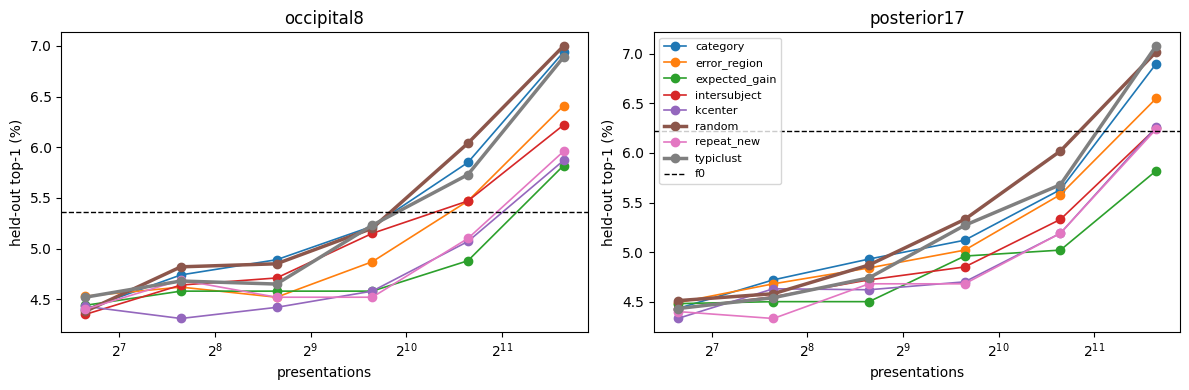

a89a73f (HEAD -> main, origin/main, origin/HEAD) results: activecal


In [9]:
# 9. Results (frozen adapter): references, AUC table, curves, plot; then copy the CSV into the repo and push it.
import matplotlib.pyplot as plt, shutil
table, curves, ref = A.summary()
print('references:'); print(ref.to_string())
print('\nPRECONDITION: random needs gain_over_f0 > 0, otherwise the policy comparison is not valid.\n')
print(table.to_string(index=False))
print('\nheld-out top-1 by budget:'); print(curves.to_string())
fig, axes = plt.subplots(1, len(MONTAGES), figsize=(6 * len(MONTAGES), 4), squeeze=False)
for ax, mon in zip(axes[0], MONTAGES):
    if mon in curves.index.get_level_values(0):
        for pol, row in curves.loc[mon].iterrows():
            ax.plot(row.index, row.values, marker='o', lw=2.5 if pol in ('random', 'typiclust') else 1.2, label=pol)
        ax.axhline(ref.xs(mon, level='montage')['f0'].mean(), color='k', ls='--', lw=1, label='f0')
    ax.set_xscale('log', base=2); ax.set_xlabel('presentations'); ax.set_ylabel('held-out top-1 (%)'); ax.set_title(mon)
axes[0][-1].legend(fontsize=8); plt.tight_layout(); plt.savefig(f'{DRIVE_BASE}/activecal_curves.png', dpi=150); plt.show()
if TOKEN:
    for f in [AL_CSV, f'{DRIVE_BASE}/activecal_curves.png']:
        shutil.copy(f, '/content/eac/results/')
    !cd /content/eac && git config user.email colab@run && git config user.name colab && git add results && git commit -qm "results: activecal" && git push -q && git log --oneline -1

## 10. Oracle (within B): is there any headroom for selection?
Random vs two cheating upper bounds on the tuning subject. If even the oracle barely beats random, selection is dead.

In [ ]:
A.run_group('oracle', [TUNE_SUB], MONTAGES, seeds=SEEDS[:2])
import pandas as pd
d = pd.read_csv(AL_CSV); o = d[d.group == 'oracle']
o.pivot_table(index=['montage', 'policy'], columns='presentations', values='top1').round(2)

## 11. Alignment (extension, outside B's go/no-go): calibrate the input, not the decoder

In [ ]:
A.run_group('align', [TUNE_SUB], MONTAGES, seeds=SEEDS[:2])
a = pd.read_csv(AL_CSV); a = a[a.group == 'align']
a.pivot_table(index=['montage', 'config'], columns='presentations', values='top1').round(2)

In [ ]:
!cp {AL_CSV} /content/eeg_active_calibration/results/activecal.csv
%cd /content/eeg_active_calibration
!git add results && git commit -qm "results: oracle + align" && git push -q